# M2Doc — Multi-Modal Document Layout Analysis Pipeline

Pipeline phân tích layout tài liệu đa phương thức bằng **M2Doc** (công bố tại **AAAI 2024** bởi SCUT HCIILAB & Alibaba Group), model mặc định: `Cascade Mask R-CNN (ResNet-50 Backbone)`.

Notebook thực hiện quy trình hoàn chỉnh:
1. **Chạy inference**: Phát hiện các khối layout tài liệu dựa trên sự kết hợp giữa đặc trưng thị giác (visual features) và đặc trưng văn bản ngữ nghĩa (textual features từ Multilingual BERT), xuất kết quả JSON chuẩn COCO.
2. **Đánh giá metric**: Đánh giá theo chuẩn Strict (khớp vị trí IoU >= 0.5 và đúng nhãn) và Loose (chỉ vị trí), tính toán mAP@[0.5:0.95] và mAP@0.5 theo chuẩn COCO, vẽ biểu đồ phân tích.
3. **Trực quan hóa**: Đối chiếu ảnh Ground Truth và dự đoán của M2Doc cạnh nhau để đánh giá trực quan chất lượng nhận diện.

### Kiến trúc Đa phương thức (Multi-Modal Fusion)
- **Early-Fusion (Pixel-level)**: Sử dụng Multilingual BERT (`bert-base-multilingual-cased`) mã hóa các từ và bounding box tương ứng thành biểu diễn lưới (`chargrid_map`), sau đó hòa trộn trực tiếp vào các tầng đặc trưng sớm của ResNet-50.
- **Late-Fusion (Block-level)**: Tại tầng RoI Head (Cascade Mask R-CNN), tính ma trận tương quan IoU giữa các bounding box đề xuất và khối văn bản để chiếu đặc trưng ngữ nghĩa vào từng vùng đối tượng trước khi phân loại và hồi quy.
- **Taxonomy Mapping**: Do model M2Doc được huấn luyện trực tiếp trên tập dữ liệu chuẩn DocLayNet, 11 nhãn đầu ra khớp hoàn toàn 1-1 với 11 danh mục của DocLayNet (Caption, Footnote, Formula, List-item, Page-footer, Page-header, Picture, Section-header, Table, Text, Title).

In [1]:
from pathlib import Path
import subprocess
import sys

# Khởi tạo đường dẫn gốc project
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "methods").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "methods").is_dir():
    raise FileNotFoundError("Không tìm thấy thư mục gốc repository; hãy mở notebook từ project DO-AN-261.")

METHOD = "m2doc"
DATASET = "doclaynet"
SPLIT = "train"
IOU_THRESHOLD = 0.5
LIMIT = 5  # 0: toàn bộ ảnh trong tập dữ liệu; hoặc giới hạn số ảnh (vd: 20 để test nhanh)
FORCE_INFERENCE = False  # True: chạy lại inference và ghi đè; False: bỏ qua ảnh đã có prediction
FIGURE_LIMIT = 5

PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / METHOD / DATASET
FIGURES_DIR = ROOT / "outputs" / "reports" / f"{METHOD}_{DATASET}"
print(f"Project: {ROOT}")
print(f"Pipeline: {METHOD} | {DATASET}/{SPLIT} | IoU >= {IOU_THRESHOLD}")
print(f"Inference: {'force rerun' if FORCE_INFERENCE else 'skip existing predictions'}")
print(f"Predictions: {PREDICTIONS_DIR}")
print(f"Figures: {FIGURES_DIR}")

Project: D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261
Pipeline: m2doc | doclaynet/train | IoU >= 0.5
Inference: skip existing predictions
Predictions: D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\outputs\predictions\m2doc\doclaynet
Figures: D:\Học kì 1 năm 4\Đồ án chuyên ngành\DO-AN-261\outputs\reports\m2doc_doclaynet


## 0. Kiểm tra mã nguồn, môi trường và tự động tải trọng số (Setup & Auto-Download)

Tế bào này kiểm tra sự tồn tại của thư mục mã nguồn M2Doc MMDetection, bộ trọng số chính thức (Cascade Mask R-CNN ResNet-50) và tập dữ liệu. Nếu chưa có file trọng số pre-trained, hệ thống sẽ tự động tải về từ Google Drive thông qua `gdown` để người dùng có thể chạy trực tiếp toàn bộ notebook mà không cần thao tác thủ công.

In [ ]:
import subprocess
import sys
from pathlib import Path

# 1. Kiểm tra và tự động clone mã nguồn MMDetection tùy biến của M2Doc
mmdet_dir = ROOT / "methods" / "m2doc" / "mmdetection"
if not mmdet_dir.is_dir() or not (mmdet_dir / "mmdet").is_dir():
    print("[Setup] Chưa tìm thấy mã nguồn MMDetection của M2Doc. Đang tự động clone từ GitHub...")
    import tempfile
    import shutil
    with tempfile.TemporaryDirectory() as tmpdir:
        clone_cmd = ["git", "clone", "--depth", "1", "https://github.com/johnning2333/M2Doc.git", tmpdir]
        subprocess.check_call(clone_cmd)
        src_mmdet = Path(tmpdir) / "mmdetection"
        if src_mmdet.is_dir():
            shutil.copytree(src_mmdet, mmdet_dir, dirs_exist_ok=True)
            print("[OK] Clone và thiết lập mã nguồn MMDetection thành công!")
        else:
            raise RuntimeError("Không tìm thấy thư mục mmdetection trong repository M2Doc vừa clone.")
else:
    print(f"[OK] Thư mục mã nguồn M2Doc MMDetection: {mmdet_dir.name}")

# 2. Kiểm tra thư viện gdown
try:
    import gdown
except ImportError:
    print("[Setup] Đang cài đặt thư viện gdown...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "gdown"])
    import gdown

# 3. Kiểm tra và tự động tải trọng số pre-trained nếu chưa có
weights_dir = ROOT / "methods" / "m2doc" / "weights"
weights_dir.mkdir(parents=True, exist_ok=True)
weights_file = weights_dir / "cascade_mask_rcnn_m2doc_r50.pth"
GDRIVE_WEIGHTS_ID = "14cf3cmVMWTG8g6w0qMd_lkKYfyR0EDX-"

if not weights_file.exists() or weights_file.stat().st_size < 1000000:
    print("[Setup] Chưa có file trọng số M2Doc. Đang tự động tải về từ Google Drive...")
    print(f"[Setup] Target: {weights_file}")
    gdown.download(id=GDRIVE_WEIGHTS_ID, output=str(weights_file), quiet=False)
    if weights_file.exists() and weights_file.stat().st_size > 1000000:
        print(f"[OK] Tải trọng số thành công ({weights_file.stat().st_size / (1024*1024):.2f} MB)!")
    else:
        raise FileNotFoundError("Không thể tải trọng số tự động. Vui lòng tải thủ công theo README.md.")
else:
    print(f"[OK] File trọng số đã sẵn sàng: {weights_file.name} ({weights_file.stat().st_size / (1024*1024):.2f} MB)")

# 4. Kiểm tra tập dữ liệu DocLayNet
images_dir = ROOT / "datasets" / DATASET / "processed" / "images"
if not images_dir.is_dir() or not any(images_dir.glob("*.png")):
    print(f"[Cảnh báo] Chưa tìm thấy ảnh tại: {images_dir}. Hãy đảm bảo đã chuẩn bị dataset trước khi chạy inference.")
else:
    num_images = len(list(images_dir.glob("*.png")))
    print(f"[OK] Tập dữ liệu {DATASET} sẵn sàng ({num_images} ảnh).")


## 1. Prediction

Chạy layout detection bằng script `methods/m2doc/src/run_inference.py`. Script nạp model Cascade Mask R-CNN kết hợp mạng trích xuất text grid BERT và sinh kết quả dự đoán ra `outputs/predictions/m2doc/<dataset>/`.

In [ ]:
inference_script = ROOT / "methods" / METHOD / "src" / "run_inference.py"
command = [
    sys.executable,
    str(inference_script),
    "--dataset", DATASET,
    "--limit", str(LIMIT),
    "--force" if FORCE_INFERENCE else "--skip-existing",
]
print("Running:", " ".join(command))
res = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(res.stdout)
print(f"Predictions: {PREDICTIONS_DIR}")

Running: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\m2doc\src\run_inference.py --dataset doclaynet --limit 20 --skip-existing


Dataset: doclaynet
Total target images: 20
Output directory: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\m2doc\doclaynet
Threshold: 0.3
Device: cpu
Use OCR: True
Loading M2Doc model from: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\m2doc\weights\cascade_mask_rcnn_m2doc_r50.pth
encoder.layer.11.attention.self.query.weight
encoder.layer.11.attention.self.query.bias
encoder.layer.11.attention.self.key.weight
encoder.layer.11.attention.self.key.bias
encoder.layer.11.attention.self.value.weight
encoder.layer.11.attention.self.value.bias
encoder.layer.11.attention.output.dense.weight
encoder.layer.11.attention.output.dense.bias
encoder.layer.11.attention.output.LayerNorm.weight
encoder.layer.11.attention.output.LayerNorm.bias
encoder.layer.11.intermediate.dense.weight
encoder.layer.11.intermediate.dense.bias
encoder.layer.11.output.dense.weight
encoder.layer.11.output.dense.bias
encoder.layer.11.output.LayerNorm.weight
encoder.layer.11.output.LayerNorm.bias
M2Doc mode

## 2. Metrics and Evaluation Chart

Đánh giá kết quả trên tập ảnh vừa thực thi inference (`outputs/predictions/m2doc/doclaynet/`).
- **Strict**: Yêu cầu khớp cả tọa độ (IoU >= threshold) và đúng nhãn layout.
- **Loose**: Chỉ đánh giá khả năng định vị (localization), bỏ qua nhãn.
- **COCO mAP**: mAP@[.5:.95] và mAP@.5 theo tiêu chuẩn COCO benchmark.
- **Biểu đồ**: Trực quan hóa Precision, Recall, F1 theo từng class và so sánh Strict vs Loose.

Running evaluation:


Evaluation: m2doc on doclaynet/train | 20 images | GT=189 boxes | Predictions=207 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.845  Recall=0.926  F1=0.884  TP=175 FP=32 FN=14  mean IoU=0.937
Macro (mean across 9 ground-truth classes): Precision=0.694  Recall=0.817  F1=0.727
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Text                   103     106     95     11      8    0.896    0.922    0.909
Section-header          30      40     29     11      1    0.725    0.967    0.829
Table                   18      19     18      1      0    0.947    1.000    0.973
Page-footer             15      16     14      2      1    0.875    0.933    0.903
Picture                 10      12      9      3      1    0.750    0.900    0.818
Page-header              6       5      5      0      1    1.000    0.833    0.909
Title                    5       5      4      1      1    0.800    0.800    0.800
Caption                  1     

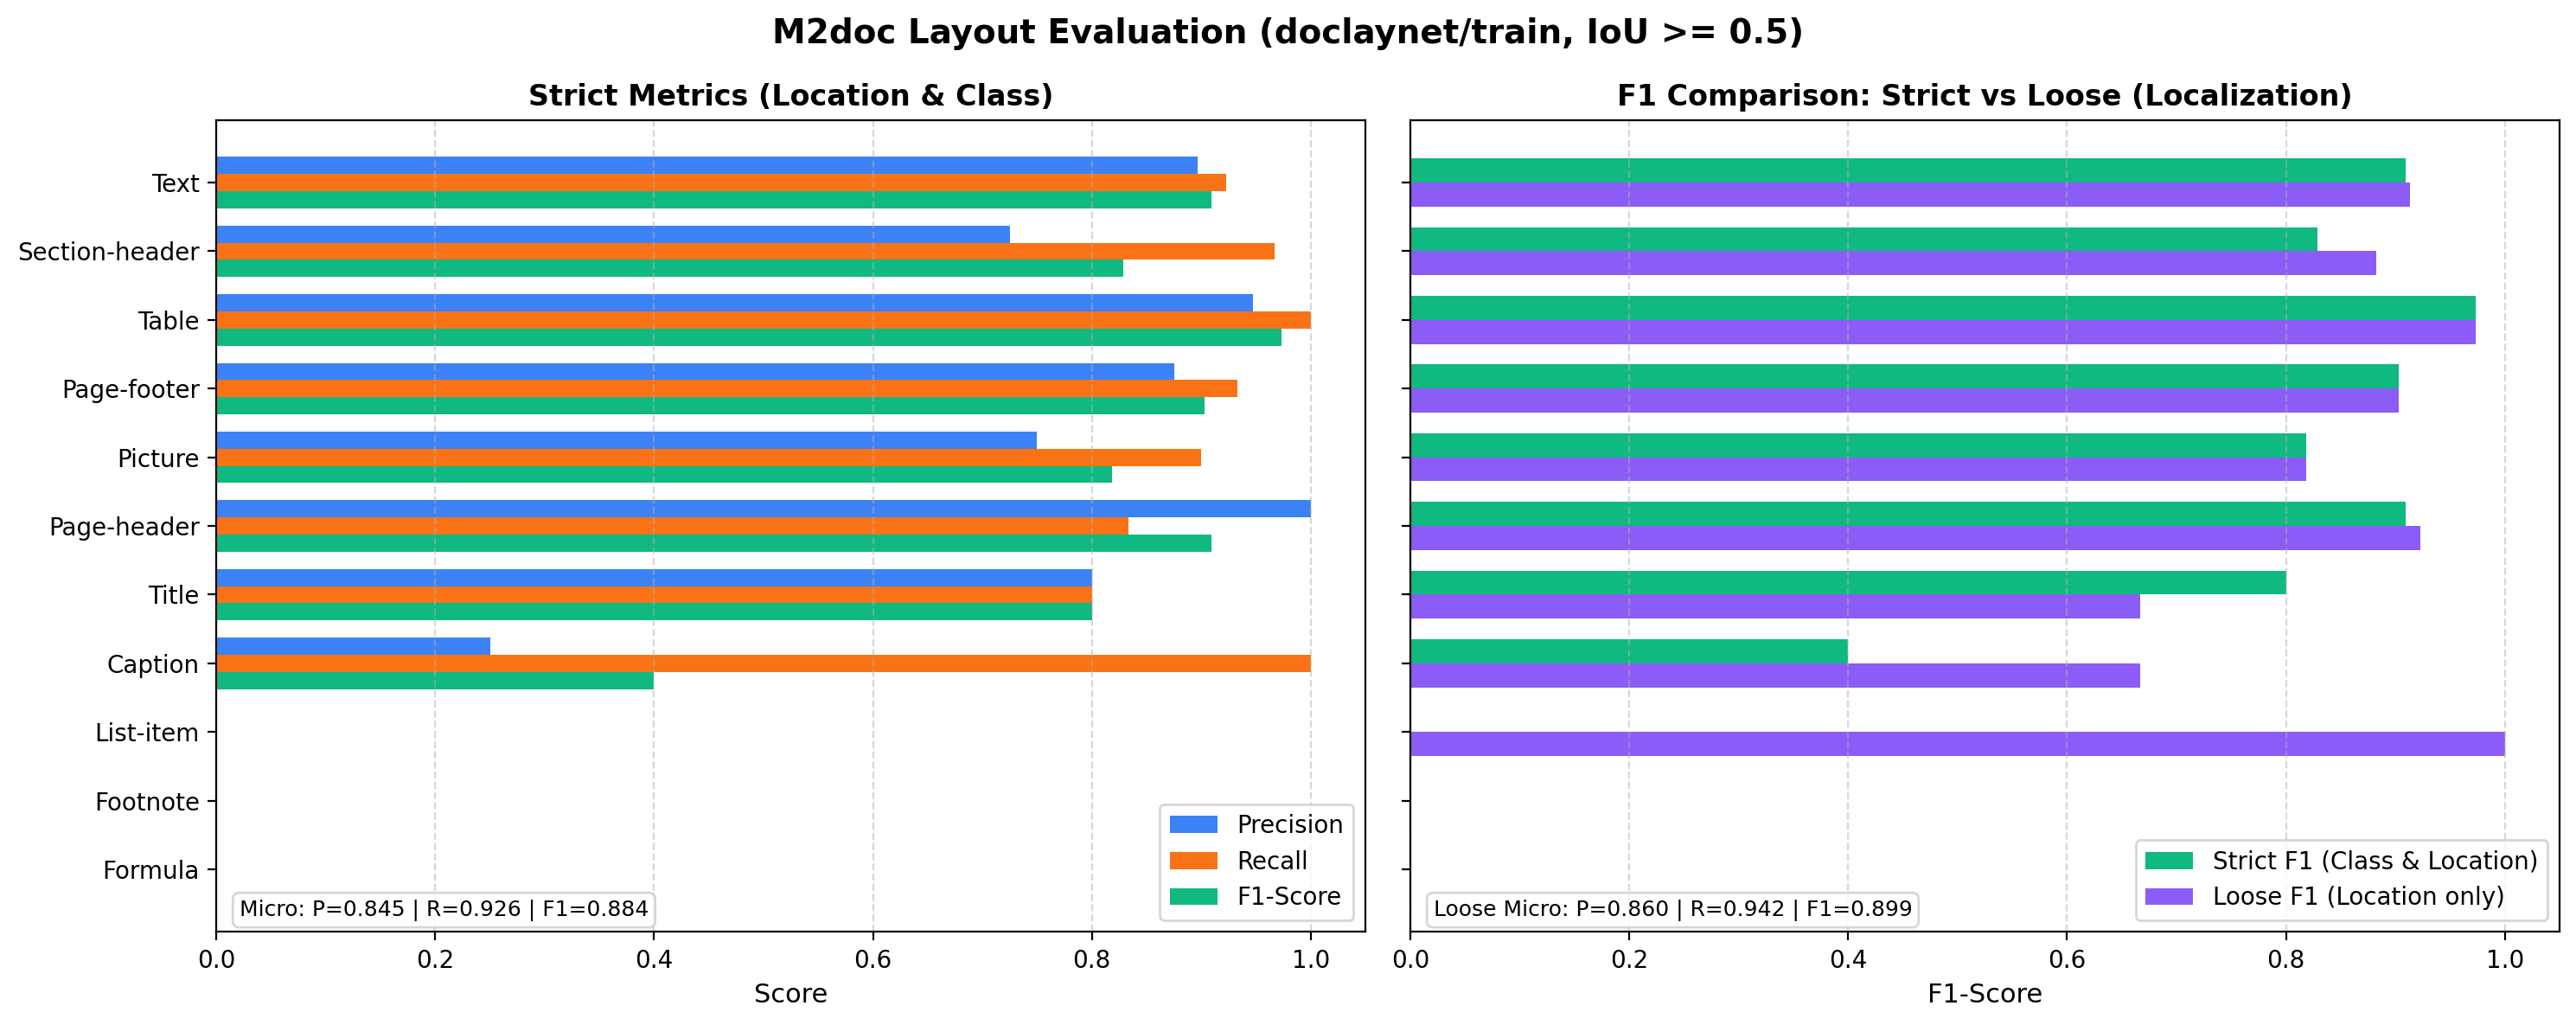

In [ ]:
eval_script = ROOT / "scripts" / "evaluate_predictions.py"
eval_command = [
    sys.executable,
    str(eval_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--iou-threshold", str(IOU_THRESHOLD),
    "--loose",
    "--allow-incomplete",
    "--plot",
]
print("Running evaluation:")
res = subprocess.run(eval_command, cwd=ROOT, capture_output=True, text=True, check=True)
print(res.stdout)

# Hiển thị biểu đồ đánh giá
chart_file = FIGURES_DIR / "metrics_chart.png"
if chart_file.is_file():
    from IPython.display import Image as DisplayImage, display
    print(f"Evaluation Chart ({chart_file}):")
    display(DisplayImage(filename=str(chart_file)))

## 3. Ground Truth vs. Prediction Examples

Trực quan hóa đối chiếu ảnh Ground Truth và kết quả dự đoán của M2Doc. Ảnh kết quả được lưu tại `outputs/reports/m2doc_doclaynet/`.

Running: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\scripts\visualize_predictions.py --method m2doc --dataset doclaynet --split train --limit 20 --output-dir D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\m2doc_doclaynet


[viz] Ve 20 anh (m2doc vs ground truth) tu D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\scripts\..\..\outputs\predictions\m2doc\doclaynet
  [ok] 0.png
  [ok] 1.png
  [ok] 10.png
  [ok] 100.png
  [ok] 101.png
  [ok] 1002.png
  [ok] 1003.png
  [ok] 1004.png
  [ok] 1005.png
  [ok] 1007.png
  [ok] 1008.png
  [ok] 1009.png
  [ok] 1010.png
  [ok] 1011.png
  [ok] 1012.png
  [ok] 1013.png
  [ok] 1014.png
  [ok] 1015.png
  [ok] 1016.png
  [ok] 1018.png
[viz] Xong. Anh luu tai D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\m2doc_doclaynet

Ví dụ ảnh đối chiếu: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\m2doc_doclaynet\0.png


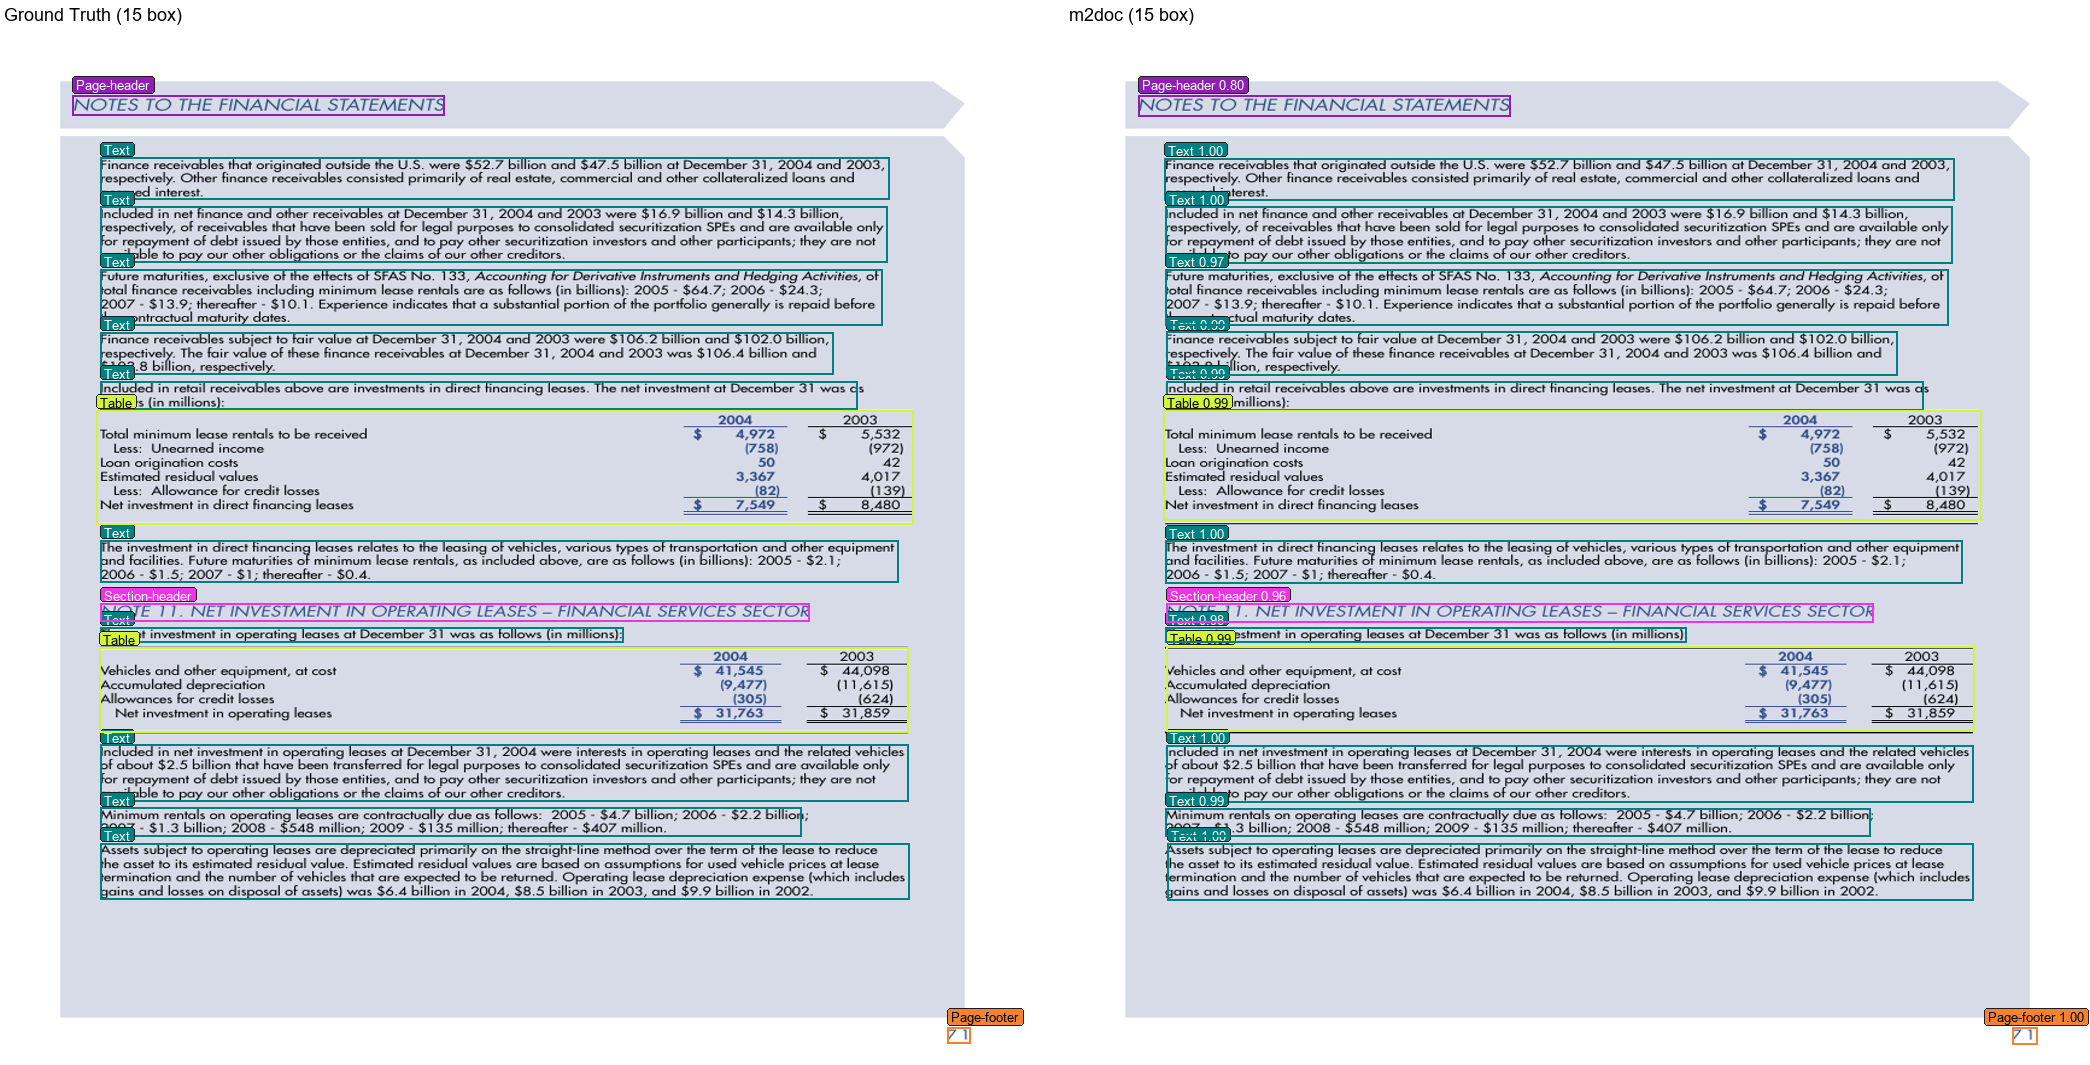

Ví dụ ảnh đối chiếu: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\m2doc_doclaynet\1.png


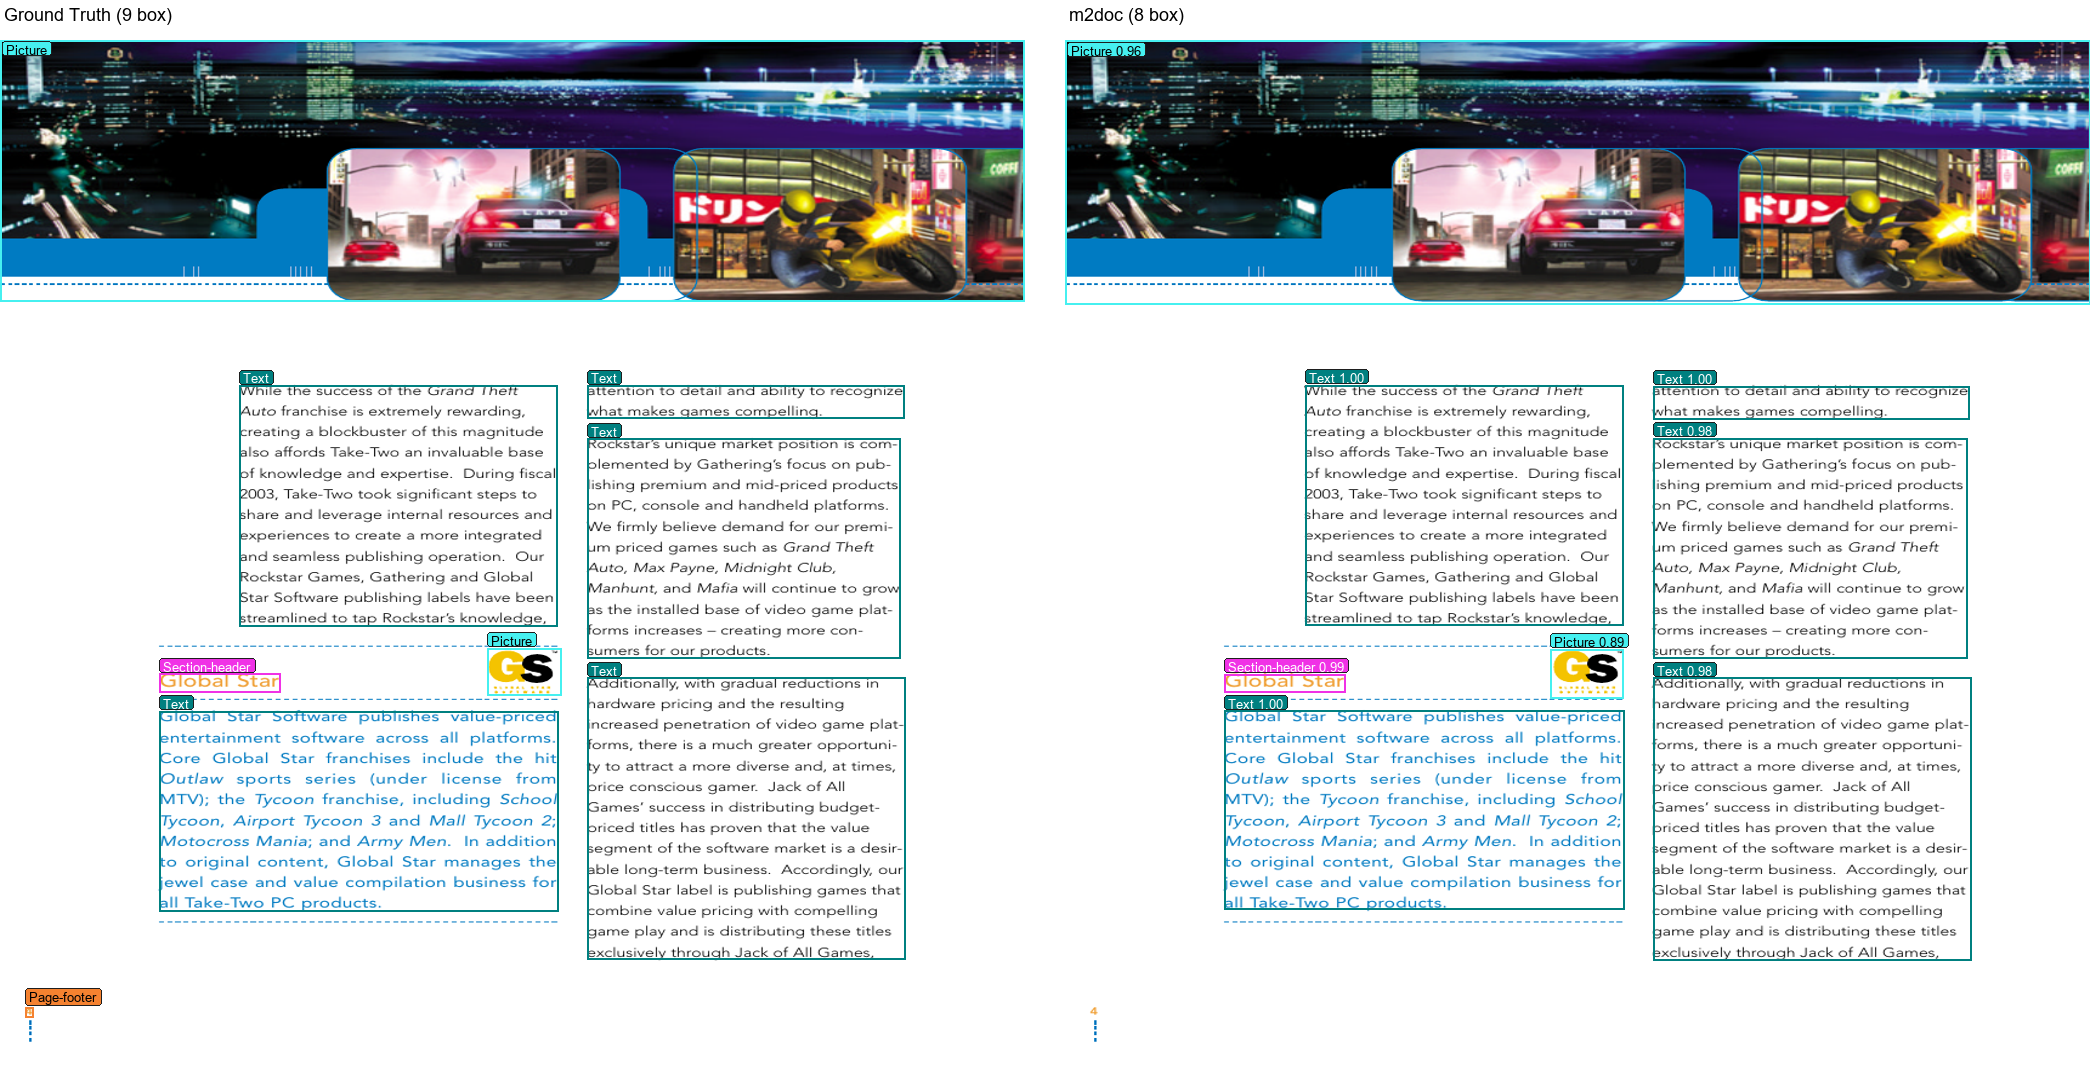

In [ ]:
viz_script = ROOT / "visualization" / "scripts" / "visualize_predictions.py"
viz_command = [
    sys.executable,
    str(viz_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--limit", str(FIGURE_LIMIT),
    "--output-dir", str(FIGURES_DIR),
]
print("Running:", " ".join(viz_command))
res = subprocess.run(viz_command, cwd=ROOT, capture_output=True, text=True, check=True)
print(res.stdout)

# Hiển thị một số ảnh minh họa đối chiếu Ground Truth vs Prediction
from IPython.display import Image as DisplayImage, display
sample_images = sorted(FIGURES_DIR.glob("*.png"))
sample_images = [img for img in sample_images if img.name != "metrics_chart.png"]
if sample_images:
    for img_path in sample_images[:2]:
        print(f"Ví dụ ảnh đối chiếu: {img_path}")
        display(DisplayImage(filename=str(img_path)))